<a href="https://colab.research.google.com/github/divyamsh8/DAV_LAB/blob/main/DAV_LAB_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [58]:
import pandas as pd

import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder , MinMaxScaler
from sklearn.decomposition import PCA
print("Librearies imported sucessfully")


Librearies imported sucessfully


In [59]:
data = pd.DataFrame({
    "Study_Hours" : [2,4,5,7,8,10],
    "Attendance_Percent": [50,60,65,75,85,95],
    "Assignment_Score": [35,45,55,65,80,95],
    "Final_Marks": [38,48,56,68,82,94]
})
display(data)

,Study_Hours,Attendance_Percent,Assignment_Score,Final_Marks
0,2,50,35,38
1,4,60,45,48
2,5,65,55,56
3,7,75,65,68
4,8,85,80,82
5,10,95,95,94


In [60]:
features =data[["Study_Hours","Attendance_Percent","Assignment_Score"]]
print(features.min())
print(features.max())

Study_Hours            2
Attendance_Percent    50
Assignment_Score      35
dtype: int64
Study_Hours           10
Attendance_Percent    95
Assignment_Score      95
dtype: int64


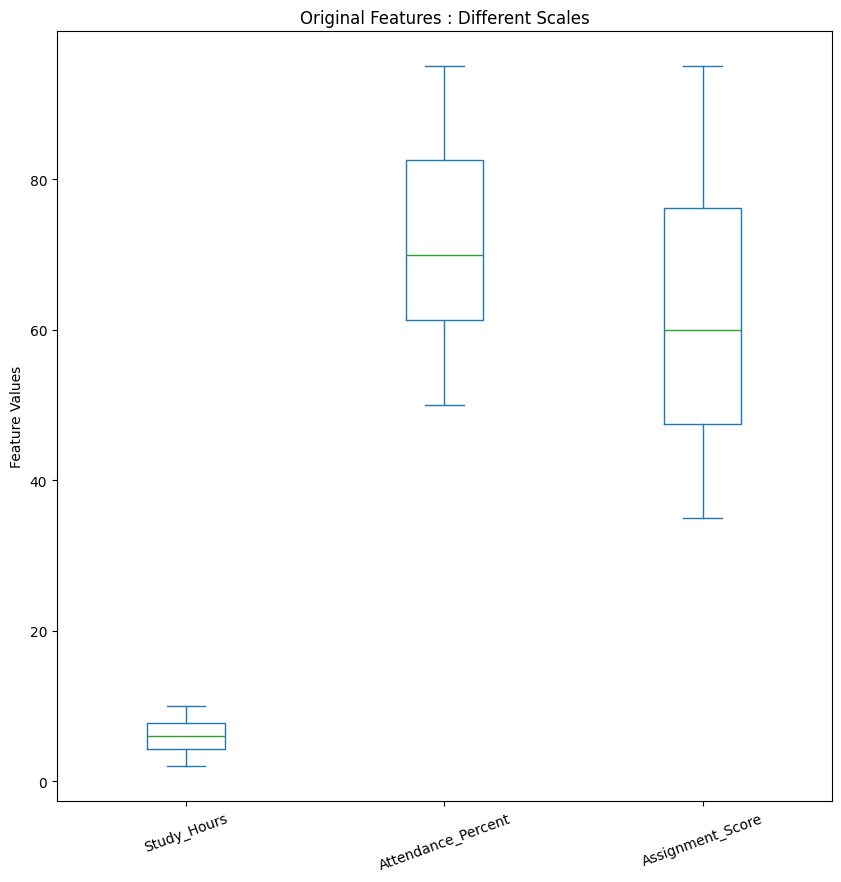

In [61]:
features.plot(kind="box",figsize=(10,10))
plt.title("Original Features : Different Scales")
plt.ylabel("Feature Values")
plt.xticks(rotation=20)
plt.show()

In [62]:

normalizer=MinMaxScaler()
normalized_array = normalizer.fit_transform(features)
normalized_df=pd.DataFrame(normalized_array,columns=features.columns,index=features.index)
display(normalized_df.round(3))

,Study_Hours,Attendance_Percent,Assignment_Score
0,0.000,0.000,0.000
1,0.250,0.222,0.167
2,0.375,0.333,0.333
3,0.625,0.556,0.500
4,0.750,0.778,0.750
5,1.000,1.000,1.000


In [63]:
print("Minimum after normalization")
print(normalized_df.min())
print("Maximum after normalization")
print(normalized_df.max())

Minimum after normalization
Study_Hours           0.0
Attendance_Percent    0.0
Assignment_Score      0.0
dtype: float64
Maximum after normalization
Study_Hours           1.0
Attendance_Percent    1.0
Assignment_Score      1.0
dtype: float64


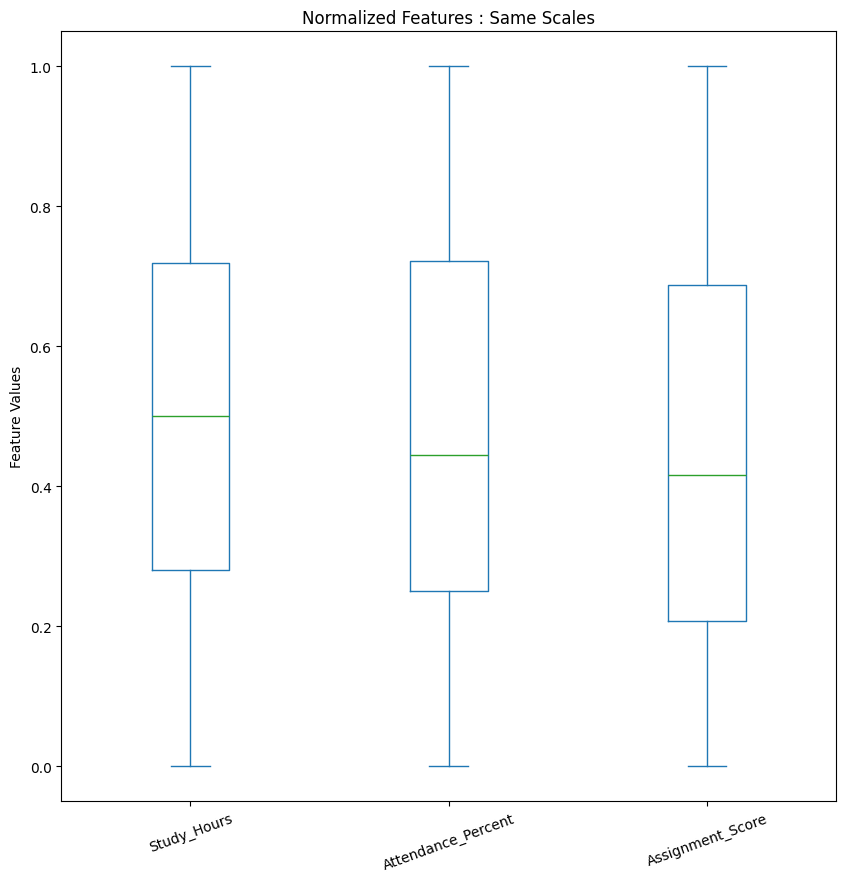

In [64]:
normalized_df.plot(kind="box",figsize=(10,10))
plt.title("Normalized Features : Same Scales")
plt.ylabel("Feature Values")
plt.xticks(rotation=20)
plt.show()

In [65]:

standardizer=MinMaxScaler()
standardized_array = standardizer.fit_transform(features)
standardized_df=pd.DataFrame(standardized_array,columns=features.columns,index=features.index)
display(standardized_df.round(3))

,Study_Hours,Attendance_Percent,Assignment_Score
0,0.000,0.000,0.000
1,0.250,0.222,0.167
2,0.375,0.333,0.333
3,0.625,0.556,0.500
4,0.750,0.778,0.750
5,1.000,1.000,1.000


In [66]:
print("Minimum after Standardisation")
print(standardized_df.min())
print("Maximum after Standardisation")
print(standardized_df.max())

Minimum after Standardisation
Study_Hours           0.0
Attendance_Percent    0.0
Assignment_Score      0.0
dtype: float64
Maximum after Standardisation
Study_Hours           1.0
Attendance_Percent    1.0
Assignment_Score      1.0
dtype: float64


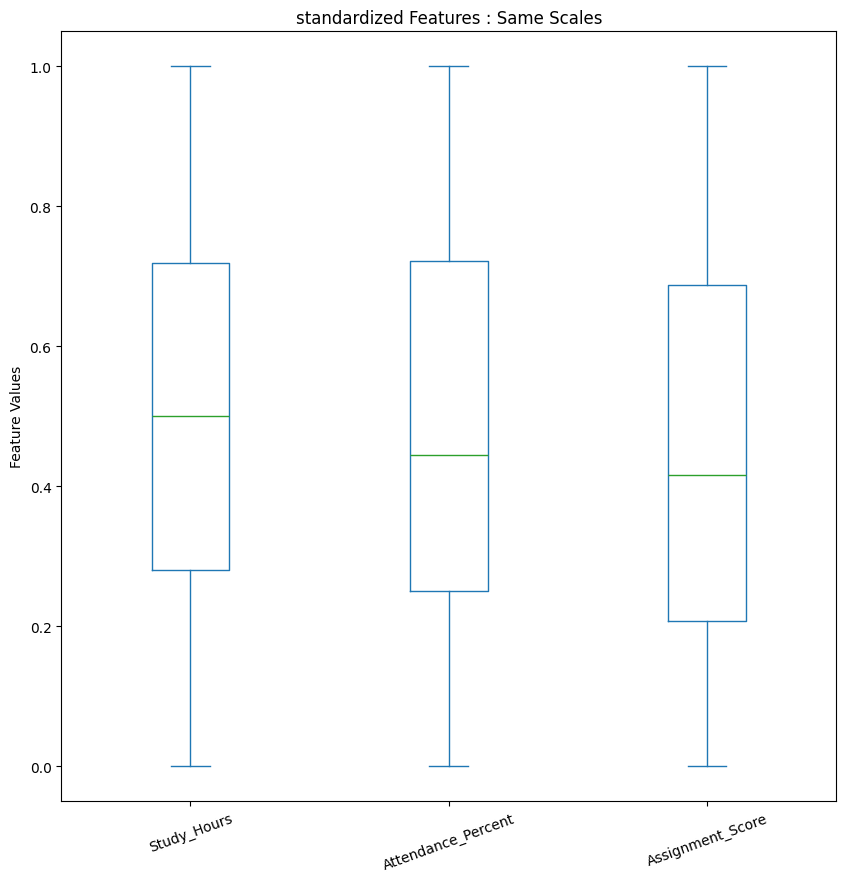

In [67]:
standardized_df.plot(kind="box",figsize=(10,10))
plt.title("standardized Features : Same Scales")
plt.ylabel("Feature Values")
plt.xticks(rotation=20)
plt.show()

In [68]:
# Step 1 : Standardize the imput features
scaled_features = standardizer.fit_transform(features)
# Step 2 : Reduce 3 features into 2 principle components
PCA_obj = PCA(n_components=2)
# Step 3 : Transform the scaled data
pca_array = PCA_obj.fit_transform(scaled_features)
pca_df = pd.DataFrame(pca_array,columns=["PC1","PC2"])
display(pca_df.round(3))

,PC1,PC2
0,-0.831,-0.038
1,-0.463,0.023
2,-0.230,-0.001
3,0.138,0.061
4,0.484,-0.026
5,0.901,-0.019


In [69]:
variance_ratios = PCA_obj.explained_variance_ratio_
for component,ratio in zip(["PC1","PC2"],variance_ratios):
    print(f"Variance Ratio for {component} : {ratio:.2%}")
total_retained= sum(variance_ratios)
print(f"Total Variance Retained : {total_retained:.2%}")

Variance Ratio for PC1 : 99.62%
Variance Ratio for PC2 : 0.33%
Total Variance Retained : 99.96%


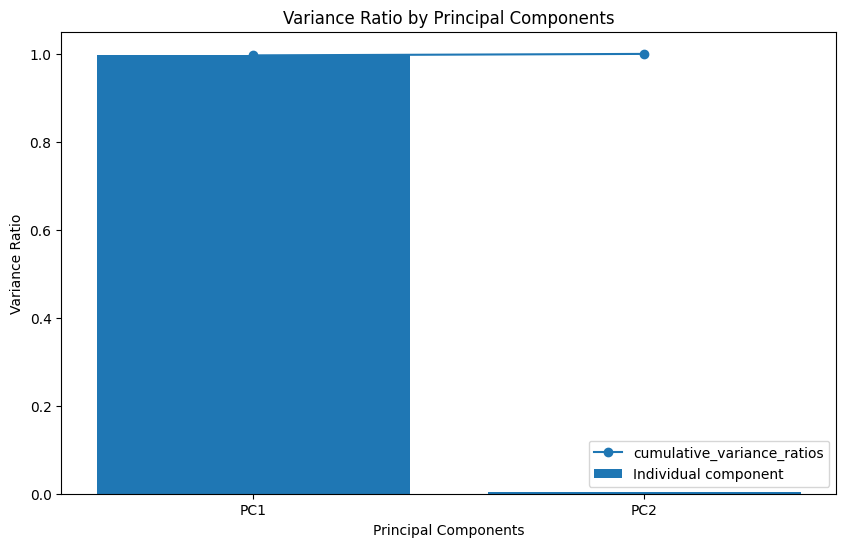

In [70]:
component_names =["PC1","PC2"]
cumulative_variance_ratios = variance_ratios.cumsum()
plt.figure(figsize=(10,6))
plt.bar(component_names,variance_ratios,label="Individual Variance Ratio")
plt.plot(component_names,cumulative_variance_ratios,marker="o")
plt.ylim(0,1.05)
plt.xlabel("Principal Components")
plt.ylabel("Variance Ratio")
plt.title("Variance Ratio by Principal Components")
plt.legend(["cumulative_variance_ratios","Individual component"])
plt.show()

In [71]:
print("Number of original input features :",features.shape[1])
print("Number of principal components :",pca_df.shape[1])
print("Orginal feature shape : ", features.shape)
print("Reduced PCA data shape : ",pca_df.shape)

Number of original input features : 3
Number of principal components : 2
Orginal feature shape :  (6, 3)
Reduced PCA data shape :  (6, 2)
